
# Unemployment Analysis with Python

## Project Overview

Unemployment is an important economic indicator that reflects labour-market conditions. Analyzing unemployment data can help identify changes over time, differences across regions, and variations between rural and urban areas.

This project uses Python to explore unemployment trends in India, investigate changes during the COVID-19 period, examine monthly patterns, and study the relationship between unemployment and labour-force participation.

## Project Objectives

- Clean and prepare the unemployment dataset.
- Explore unemployment rates using descriptive statistics.
- Visualize changes in unemployment over time.
- Compare unemployment rates across regions and area types.
- Investigate unemployment patterns before and during the COVID-19 period.
- Identify meaningful findings and potential policy implications.

## Tools and Technologies

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Google Colab
- Exploratory Data Analysis (EDA)


In [27]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120

print("All libraries imported successfully.")


All libraries imported successfully.



## Dataset Loading

The dataset used in this project contains unemployment-related observations from different Indian regions. It includes unemployment rates, estimated employment, labour-force participation rates, observation dates, and rural or urban classifications.

The dataset is loaded into a Pandas DataFrame for further inspection, cleaning, and exploratory data analysis.


In [28]:

# Load the unemployment dataset

file_path = "/content/Unemployment in India.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully.")
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")


Dataset loaded successfully.
Number of rows: 768
Number of columns: 7



## Initial Data Exploration

Initial exploration helps us understand the dataset's structure, column names, data types, and overall coverage. It also helps identify potential data-quality issues before preprocessing.


In [29]:

# Preview the dataset

display(df.head(10))


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural
5,Andhra Pradesh,31-10-2019,Monthly,3.52,12017412.0,43.01,Rural
6,Andhra Pradesh,30-11-2019,Monthly,4.12,11397681.0,41.00,Rural
7,Andhra Pradesh,31-12-2019,Monthly,4.38,12528395.0,45.14,Rural
8,Andhra Pradesh,31-01-2020,Monthly,4.84,12016676.0,43.46,Rural
9,Andhra Pradesh,29-02-2020,Monthly,5.91,11723617.0,42.83,Rural


In [30]:

# Inspect column names and data types

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()


Column names:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    object 
 1    Date                                     740 non-null    object 
 2    Frequency                                740 non-null    object 
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ KB


In [31]:

# Examine missing values and duplicate records

print("Missing values by column:")
display(df.isnull().sum().to_frame(name="Missing Values"))

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe().T)


Missing values by column:


,Missing Values
Region,28
Date,28
Frequency,28
Estimated Unemployment Rate (%),28
Estimated Employed,28
Estimated Labour Participation Rate (%),28
Area,28



Duplicate rows:
27

Statistical summary:


,count,mean,std,min,25%,50%,75%,max
Estimated Unemployment Rate (%),740.0,1.178795e+01,1.072130e+01,0.00,4.657500e+00,8.35,1.588750e+01,76.74
Estimated Employed,740.0,7.204460e+06,8.087988e+06,49420.00,1.190404e+06,4744178.50,1.127549e+07,45777509.00
Estimated Labour Participation Rate (%),740.0,4.263012e+01,8.111094e+00,13.33,3.806250e+01,41.16,4.550500e+01,72.57



## Data Cleaning and Preprocessing

Data cleaning improves data consistency and prepares the dataset for reliable analysis. This process includes standardizing column names, removing empty and duplicate records, converting dates into datetime format, and ensuring numerical measurements have appropriate data types.

Missing values in essential analysis fields will be handled carefully to avoid introducing misleading results.


In [32]:

# Standardize column names and text values

df.columns = df.columns.str.strip()

df = df.dropna(how="all").copy()

text_columns = df.select_dtypes(include="object").columns

for column in text_columns:
    df[column] = df[column].str.strip()

# Convert dates and numerical measurements
df["Date"] = pd.to_datetime(
    df["Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

numeric_columns = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Remove duplicate records
df = df.drop_duplicates().copy()

# Remove rows missing essential analysis fields
required_columns = [
    "Region",
    "Date",
    "Estimated Unemployment Rate (%)"
]

df = df.dropna(subset=required_columns).copy()
df.reset_index(drop=True, inplace=True)

print("Data cleaning completed.")
print("Cleaned dataset shape:", df.shape)

print("\nRemaining missing values:")
display(df.isnull().sum().to_frame(name="Missing Values"))

display(df.head())


Data cleaning completed.
Cleaned dataset shape: (740, 7)

Remaining missing values:


,Missing Values
Region,0
Date,0
Frequency,0
Estimated Unemployment Rate (%),0
Estimated Employed,0
Estimated Labour Participation Rate (%),0
Area,0


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural



## Unemployment Trends Over Time

This analysis examines how estimated unemployment rates change over the observation period. A time-series visualization helps identify periods of rising or falling unemployment and provides a foundation for investigating the changes observed during the COVID-19 period.


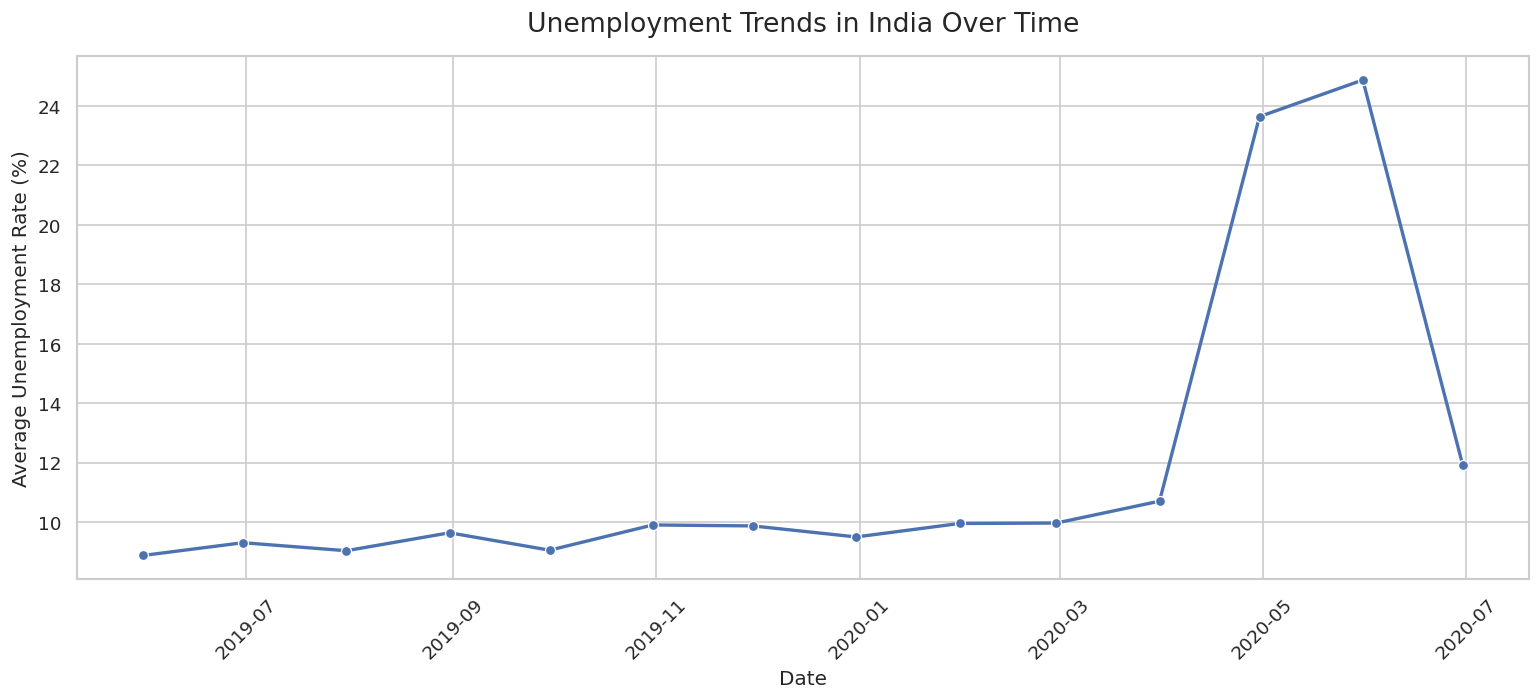

Highest average rate: 24.88 %
Lowest average rate: 8.87 %


In [33]:

# Analyze unemployment trends over time

date_trends = (
    df.groupby("Date")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_index()
)

plt.figure(figsize=(13, 6))

sns.lineplot(
    x=date_trends.index,
    y=date_trends.values,
    marker="o",
    linewidth=2
)

plt.title("Unemployment Trends in India Over Time", fontsize=16, pad=15)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Average Unemployment Rate (%)", fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Highest average rate:", round(date_trends.max(), 2), "%")
print("Lowest average rate:", round(date_trends.min(), 2), "%")



## Impact of COVID-19 on Unemployment in India

The COVID-19 pandemic disrupted economic activities and labour markets across the world. This analysis compares unemployment rates before March 2020 with rates from March 2020 onward in the available dataset.

The comparison helps identify changes between these periods. However, differences in average unemployment rates alone cannot establish that the pandemic was the only cause of those changes.


,mean,median,count
Period,,,
Before March 2020,9.51,7.12,536
March 2020 Onward,17.77,14.52,204


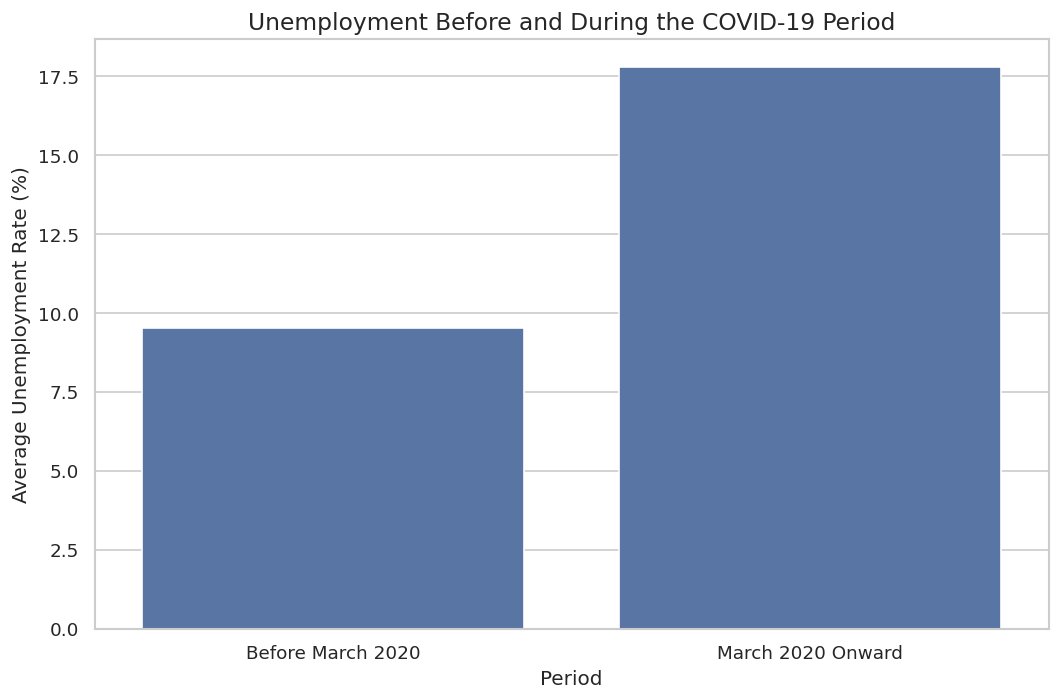

Available date range:
2019-05-31 00:00:00 to 2020-06-30 00:00:00


In [35]:

# Compare unemployment before and from the COVID-19 period onward

covid_df = df.dropna(
    subset=["Date", "Estimated Unemployment Rate (%)"]
).copy()

covid_df["Period"] = np.where(
    covid_df["Date"] < pd.Timestamp("2020-03-01"),
    "Before March 2020",
    "March 2020 Onward"
)

covid_summary = (
    covid_df.groupby("Period")["Estimated Unemployment Rate (%)"]
    .agg(["mean", "median", "count"])
    .round(2)
)

display(covid_summary)

plt.figure(figsize=(9, 6))

sns.barplot(
    data=covid_df,
    x="Period",
    y="Estimated Unemployment Rate (%)",
    errorbar=None
)

plt.title("Unemployment Before and During the COVID-19 Period", fontsize=14)
plt.xlabel("Period")
plt.ylabel("Average Unemployment Rate (%)")
plt.tight_layout()
plt.show()

print("Available date range:")
print(covid_df["Date"].min(), "to", covid_df["Date"].max())



## Monthly and Seasonal Unemployment Patterns

This analysis compares average unemployment rates across calendar months to identify months with relatively high or low unemployment in the available observations.

Monthly differences may suggest patterns worth investigating. However, confirming seasonality requires sufficient data across multiple years, because a single year's monthly variation may not represent a recurring seasonal trend.


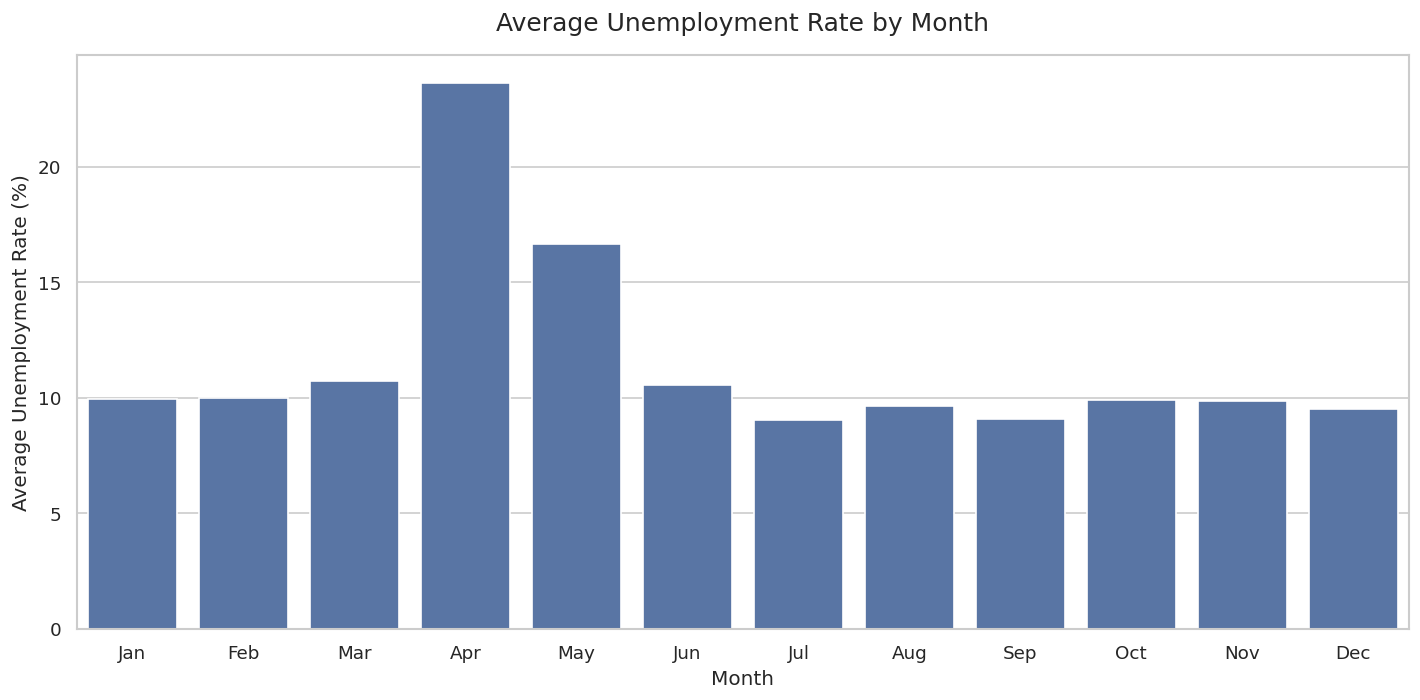

,Average Unemployment Rate (%)
Month,
1,9.95
2,9.96
3,10.70
4,23.64
5,16.65
6,10.55
7,9.03
8,9.64
9,9.05


In [37]:

# Examine unemployment rates by calendar month

seasonal_df = df.dropna(
    subset=["Date", "Estimated Unemployment Rate (%)"]
).copy()

seasonal_df["Month"] = seasonal_df["Date"].dt.month

monthly_pattern = (
    seasonal_df.groupby("Month")["Estimated Unemployment Rate (%)"]
    .mean()
    .reindex(range(1, 13))
)

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

plt.figure(figsize=(12, 6))

sns.barplot(
    x=month_names,
    y=monthly_pattern.values
)

plt.title("Average Unemployment Rate by Month", fontsize=15, pad=15)
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.tight_layout()
plt.show()

display(
    monthly_pattern.rename("Average Unemployment Rate (%)")
    .round(2)
    .to_frame()
)



## Regional Unemployment Analysis

This analysis compares average unemployment rates across the regions represented in the dataset. A regional comparison helps identify areas with relatively higher or lower unemployment rates during the observation period.

The results describe the available dataset and should not automatically be interpreted as current unemployment rankings.


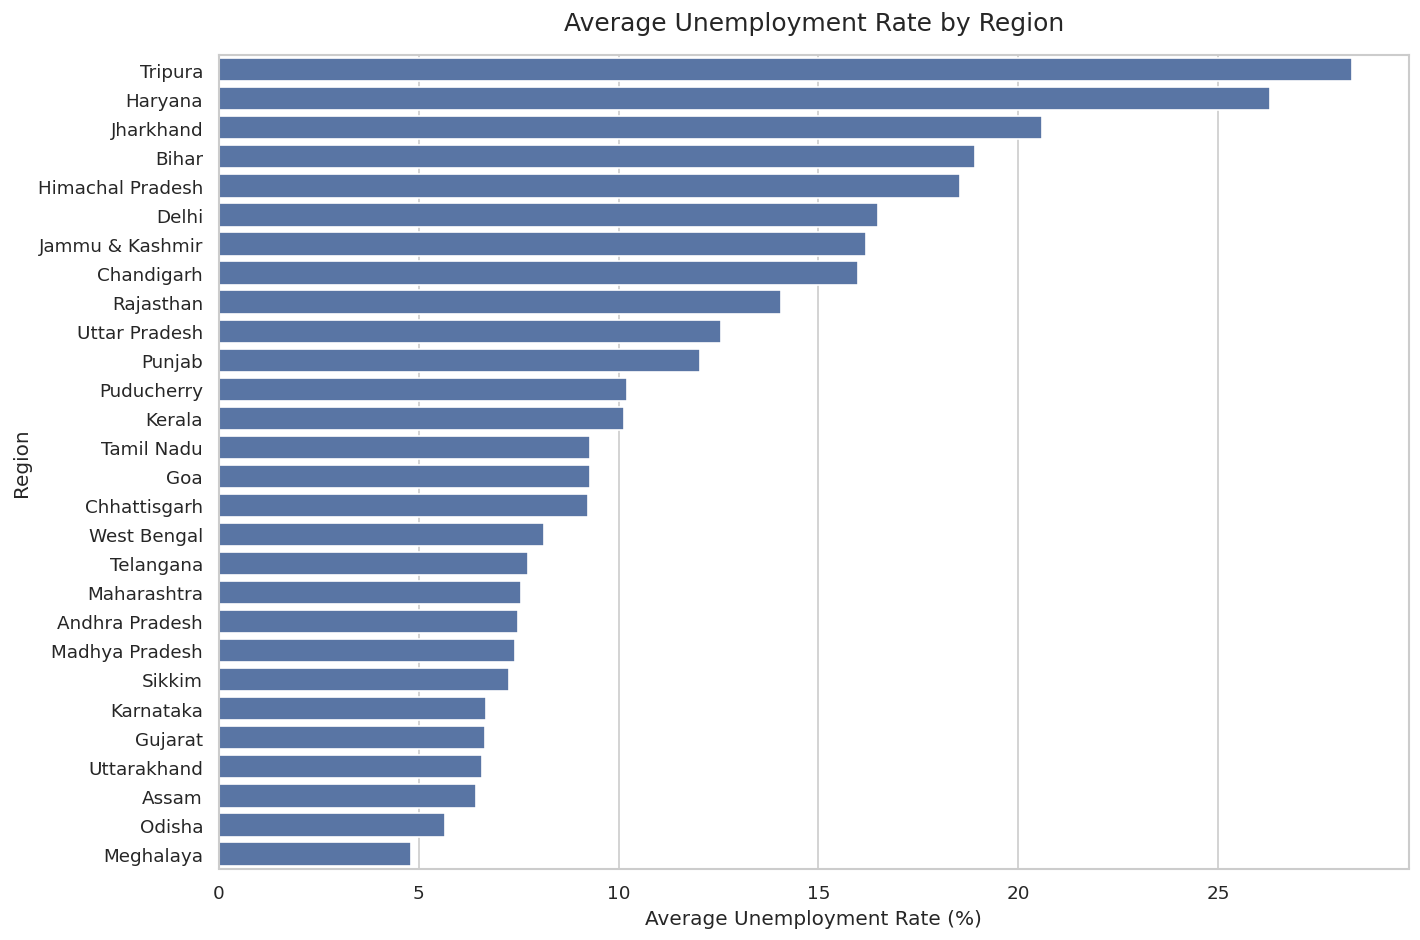

,Average Unemployment Rate (%)
Region,
Tripura,28.35
Haryana,26.28
Jharkhand,20.58
Bihar,18.92
Himachal Pradesh,18.54
Delhi,16.50
Jammu & Kashmir,16.19
Chandigarh,15.99
Rajasthan,14.06


In [38]:

# Compare unemployment rates across regions

regional_unemployment = (
    df.groupby("Region")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 8))

sns.barplot(
    x=regional_unemployment.values,
    y=regional_unemployment.index
)

plt.title("Average Unemployment Rate by Region", fontsize=15, pad=15)
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

display(
    regional_unemployment
    .rename("Average Unemployment Rate (%)")
    .round(2)
    .to_frame()
)



## Rural vs Urban Unemployment Analysis

This analysis compares estimated unemployment rates between rural and urban areas. It helps examine whether the average rates differ across area types in the available observations.


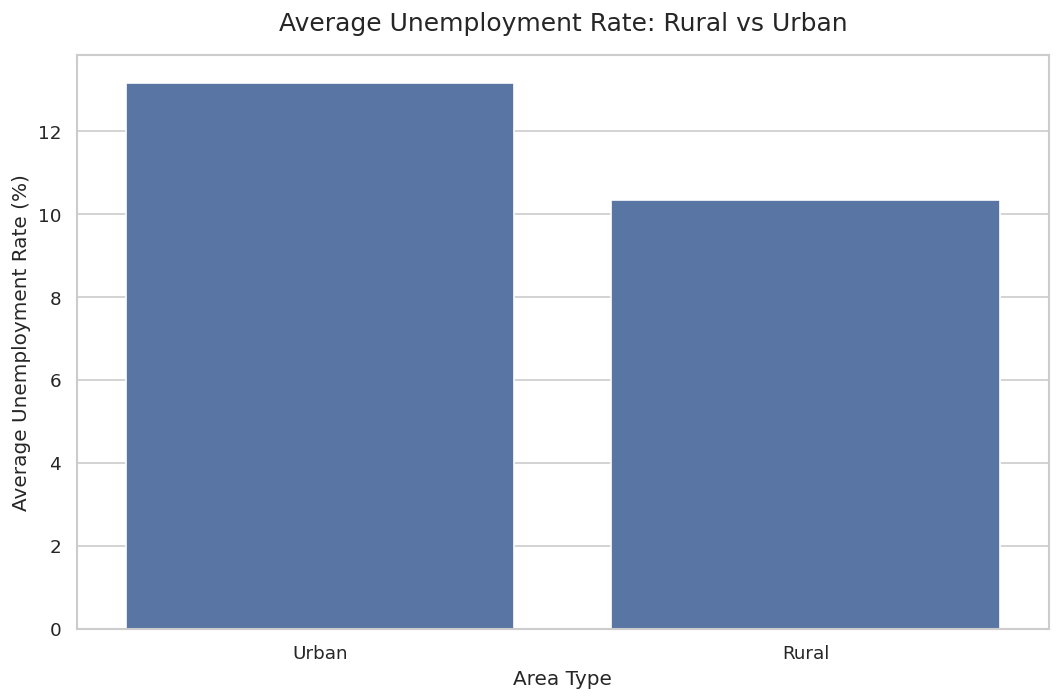

,Average Unemployment Rate (%)
Area,
Urban,13.17
Rural,10.32


In [39]:

# Compare unemployment rates by area type

area_column = "Area"

area_unemployment = (
    df.groupby(area_column)["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 6))

sns.barplot(
    x=area_unemployment.index,
    y=area_unemployment.values
)

plt.title("Average Unemployment Rate: Rural vs Urban", fontsize=15, pad=15)
plt.xlabel("Area Type")
plt.ylabel("Average Unemployment Rate (%)")
plt.tight_layout()
plt.show()

display(
    area_unemployment
    .rename("Average Unemployment Rate (%)")
    .round(2)
    .to_frame()
)



## Relationship Between Unemployment and Labour Participation

The labour participation rate represents the proportion of the relevant population that is working or actively participating in the labour market, according to the dataset's measurement methodology.

This analysis explores the relationship between estimated unemployment and labour participation using a scatter plot. It can reveal associations but cannot establish causation.


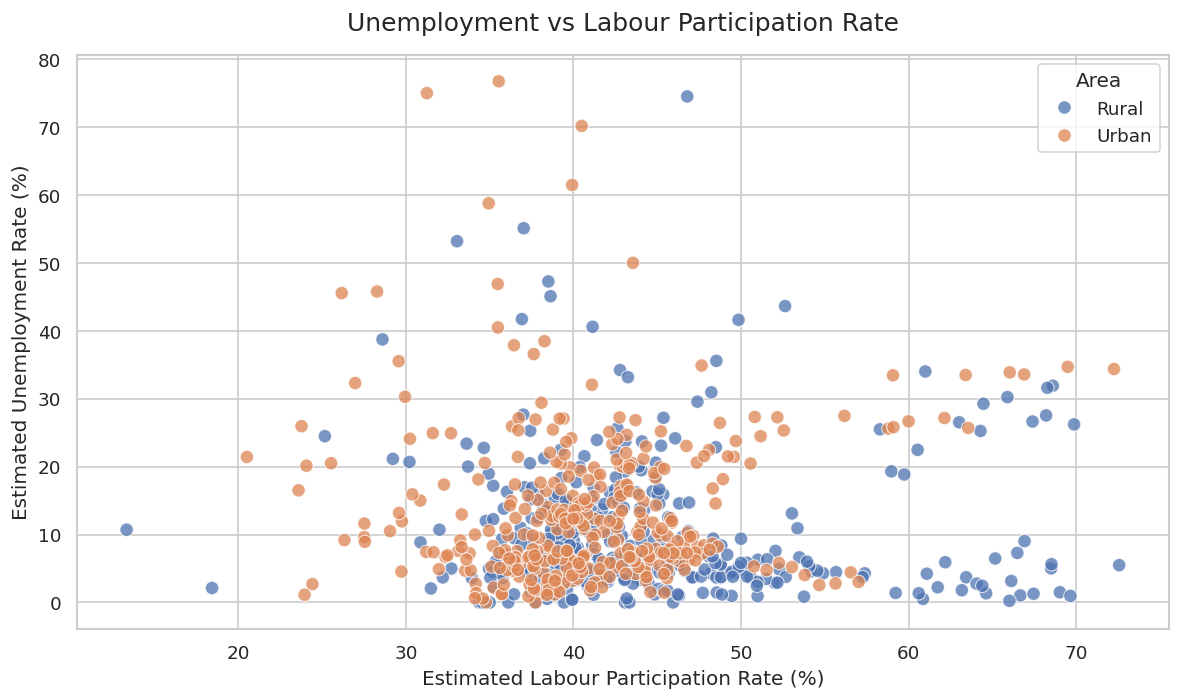

In [41]:

# Visualize unemployment and labour participation

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Estimated Labour Participation Rate (%)",
    y="Estimated Unemployment Rate (%)",
    hue="Area",
    alpha=0.75,
    s=65
)

plt.title(
    "Unemployment vs Labour Participation Rate",
    fontsize=15,
    pad=15
)
plt.xlabel("Estimated Labour Participation Rate (%)")
plt.ylabel("Estimated Unemployment Rate (%)")
plt.tight_layout()
plt.show()



## Correlation Analysis

Correlation analysis examines linear relationships between numerical variables. A heatmap provides a visual summary of the direction and strength of these relationships.

Correlation values alone do not establish causal relationships between variables.


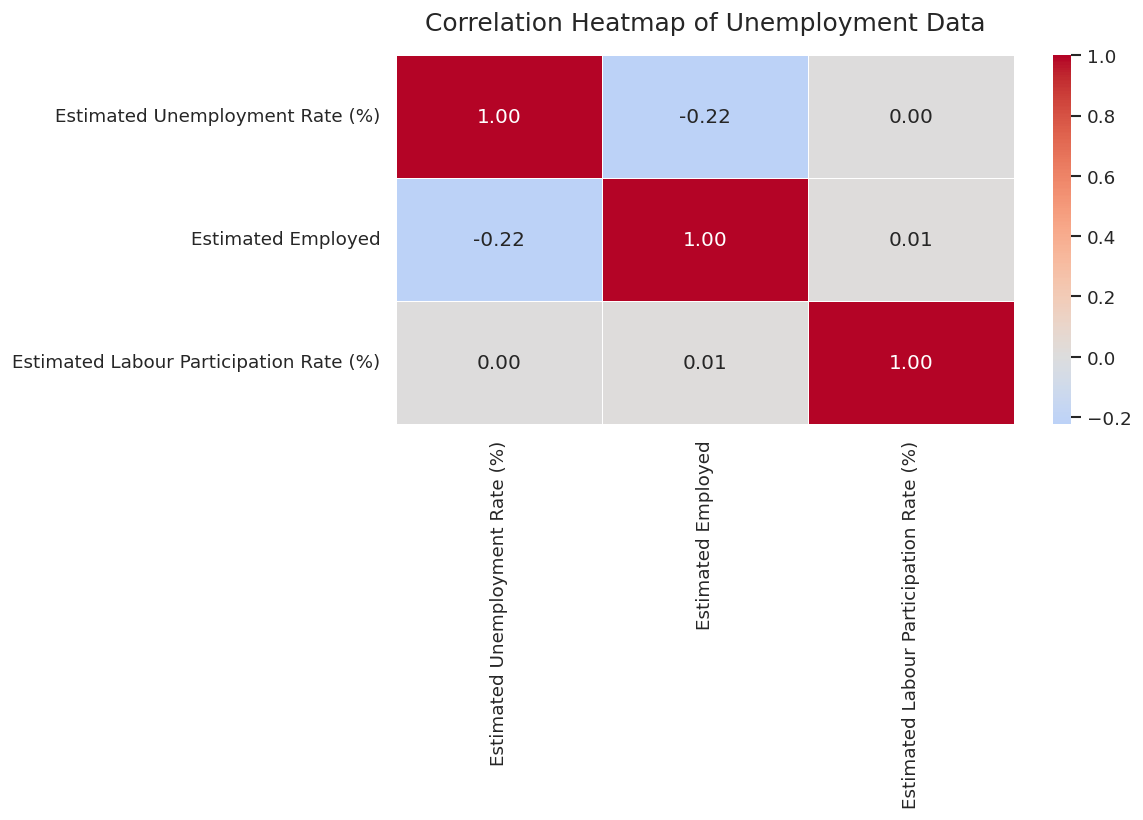

In [42]:

# Calculate correlations between numerical variables

numeric_df = df.select_dtypes(include="number")
correlation_matrix = numeric_df.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

plt.title("Correlation Heatmap of Unemployment Data", fontsize=15, pad=15)
plt.tight_layout()
plt.show()


## Key Findings

This section summarizes the main findings from the unemployment dataset, including overall unemployment levels, regional differences, rural and urban patterns, monthly variations, and the comparison between the periods before and after March 2020.

The findings are calculated from the available dataset to avoid relying on assumptions. These results describe patterns in the data and do not, by themselves, establish the causes of unemployment.

In [43]:
print("KEY FINDINGS")
print("=" * 50)

print("\n1. Dataset Overview")
print("Total records:", len(df))
print("Number of regions:", df["Region"].nunique())
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())

print("\n2. Overall Unemployment")
overall_rate = df["Estimated Unemployment Rate (%)"].mean()
print(f"Average unemployment rate: {overall_rate:.2f}%")

print("\n3. Regional Comparison")
regional_rates = df.groupby("Region")["Estimated Unemployment Rate (%)"].mean()

print("Highest average unemployment:",
      regional_rates.idxmax(),
      f"({regional_rates.max():.2f}%)")

print("Lowest average unemployment:",
      regional_rates.idxmin(),
      f"({regional_rates.min():.2f}%)")

print("\n4. Monthly Pattern")
if monthly_pattern.notna().any():
    print("Highest average month:",
          month_names[int(monthly_pattern.idxmax()) - 1],
          f"({monthly_pattern.max():.2f}%)")
    print("Lowest average month:",
          month_names[int(monthly_pattern.idxmin()) - 1],
          f"({monthly_pattern.min():.2f}%)")
else:
    print("Monthly comparison is unavailable.")

print("\n5. Rural and Urban Comparison")
if not area_unemployment.empty:
    display(
        area_unemployment.rename(
            "Average Unemployment Rate (%)"
        ).round(2).to_frame()
    )
else:
    print("Area comparison is unavailable.")

print("\n6. Before and After March 2020")
display(covid_summary)

print("\nKey findings generated successfully.")

KEY FINDINGS

1. Dataset Overview
Total records: 740
Number of regions: 28
Date range: 2019-05-31 to 2020-06-30

2. Overall Unemployment
Average unemployment rate: 11.79%

3. Regional Comparison
Highest average unemployment: Tripura (28.35%)
Lowest average unemployment: Meghalaya (4.80%)

4. Monthly Pattern
Highest average month: Apr (23.64%)
Lowest average month: Jul (9.03%)

5. Rural and Urban Comparison


,Average Unemployment Rate (%)
Area,
Urban,13.17
Rural,10.32



6. Before and After March 2020


,mean,median,count
Period,,,
Before March 2020,9.51,7.12,536
March 2020 Onward,17.77,14.52,204



Key findings generated successfully.


## Policy Implications

The analysis can help identify areas that may require further attention from policymakers.

- **Regional employment planning:** Regions with higher average unemployment may need closer investigation and targeted employment initiatives.
- **Skill development:** Vocational training and industry-relevant education can help improve access to suitable employment opportunities.
- **Rural and urban opportunities:** Differences between rural and urban unemployment rates can guide the planning of location-specific employment programmes.
- **Economic resilience:** Changes observed around the COVID-19 period highlight the importance of preparing for economic disruptions and supporting affected workers.
- **Continuous monitoring:** Regular analysis of employment indicators can help policymakers monitor trends and evaluate the progress of employment initiatives.

These are potential policy directions, not proven causal conclusions. Additional information about wages, industries, education, demographics, and economic conditions would be needed to make stronger policy recommendations.

## Conclusion

This project explored unemployment trends in India using Python and data analysis libraries such as Pandas, NumPy, Matplotlib, and Seaborn.

The analysis included data cleaning, exploratory data analysis, unemployment trends over time, a comparison of periods before and after March 2020, monthly patterns, regional differences, rural and urban comparisons, labour force participation, and correlation analysis.

The visualizations and summary statistics help reveal patterns and differences in the available data. The project also demonstrates how Python can be used to transform raw data into meaningful insights that may support further economic and social research.

Overall, this project strengthened practical skills in data preprocessing, exploratory data analysis, statistical summaries, and data visualization. The results should be interpreted in the context of the dataset's time period and limitations.